In [ ]:
The sklearn library provides an implementation of the DBSCAN algorithm for clustering, a density-based unsupervised learning technique.
                                                                      Uneven cluster sizes can occur due to the natural distribution of the data. 
                                                                      K-Means assumes clusters of similar sizes and density.




A DBSCAN clustering model fails to cluster some points. What could be the reason?

Noise in the data


K-Means clustering results change with different initializations. What could help resolve this?

Random state initialization

Random state initialization can help achieve consistent results by ensuring the initial cluster centroids are the same across different runs 
of the algorithm.


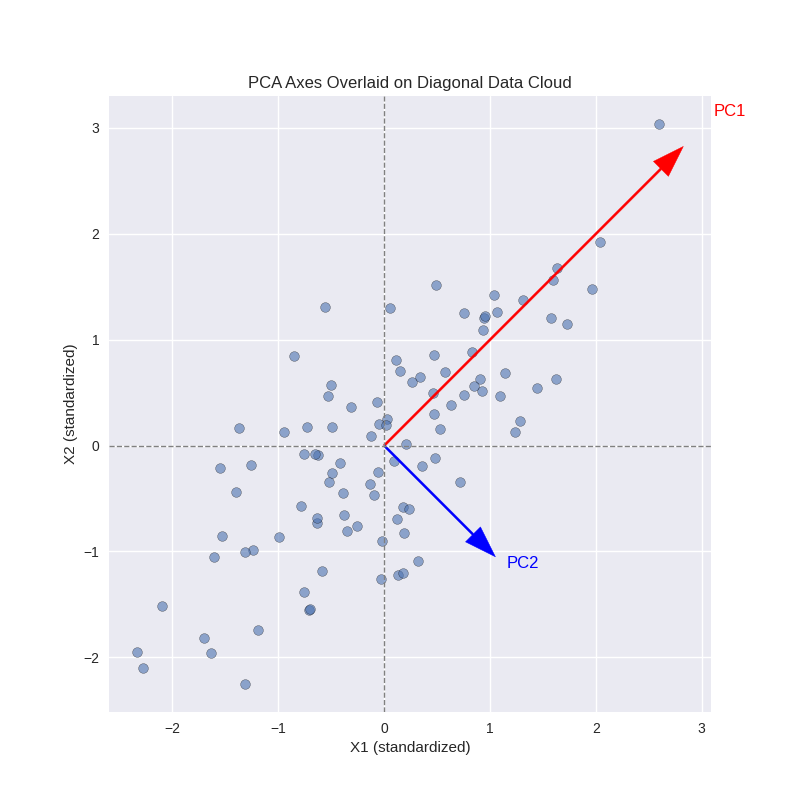

In [3]:
from IPython.display import Image, display
display(Image(filename="C:\\Users\\Rama Kumar\\Downloads\\Generated Image_PCA.png"))

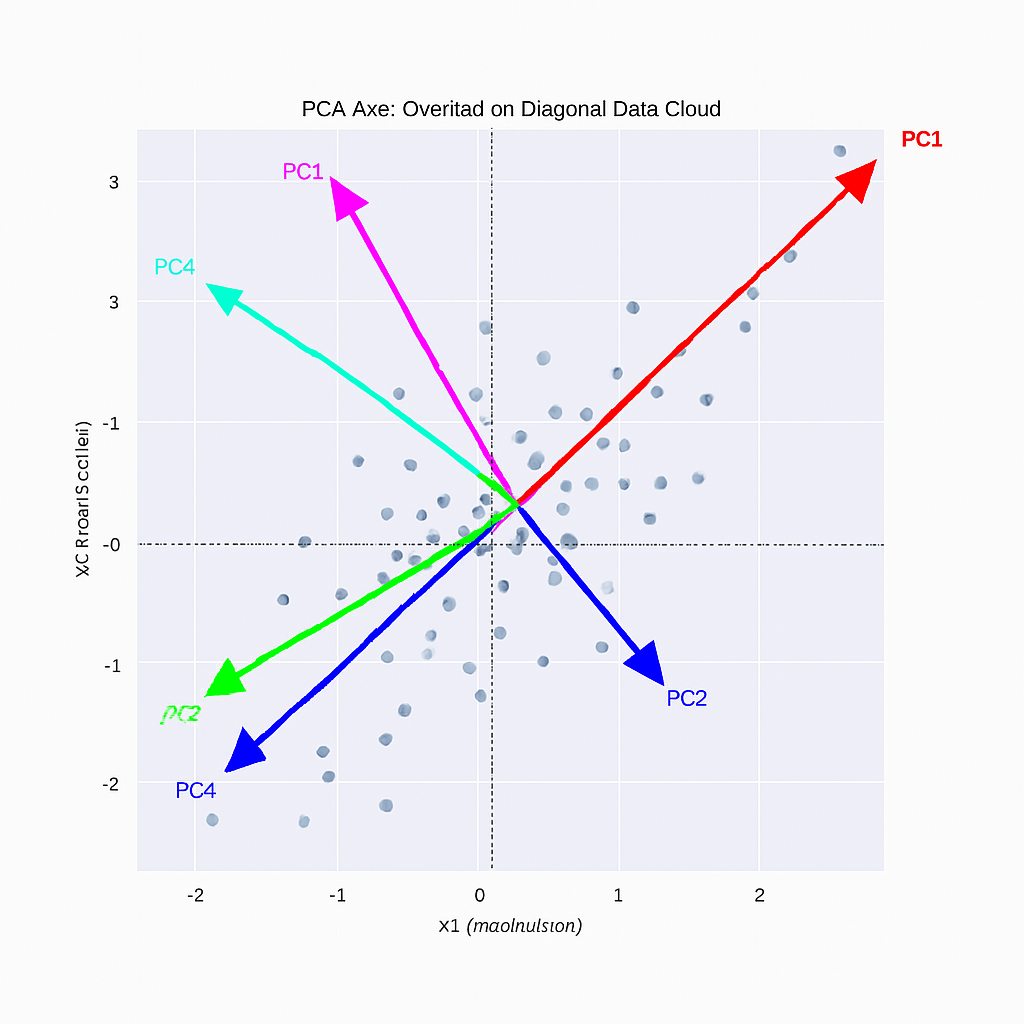

In [5]:
from IPython.display import Image, display
display(Image(filename="C:\\Users\\Rama Kumar\\Downloads\\PCA_IMAGE_2.png"))

In [ ]:
 Covariance Matrix in Simple Notation
Sigma = [
    [variance of X1, covariance of X1 and X2],
    [covariance of X2 and X1, variance of X2]
]


Or even more compactly:
Sigma = [
    [Var(X1), Cov(X1, X2)],
    [Cov(X2, X1), Var(X2)]
]


Since covariance is symmetric, Cov(X1, X2) = Cov(X2, X1), so this matrix is always symmetric.

🧠 What Each Term Means
- Var(X1): How much X1 varies on its own.
- Var(X2): How much X2 varies on its own.
- Cov(X1, X2): How much X1 and X2 vary together.
This matrix is the foundation for PCA—it’s what we diagonalize to find the principal components.


In [7]:
import numpy as np

# Step 1: Create a simple 2D dataset
X = np.array([
    [2.5, 2.4],
    [0.5, 0.7],
    [2.2, 2.9],
    [1.9, 2.2],
    [3.1, 3.0],
    [2.3, 2.7],
    [2, 1.6],
    [1, 1.1],
    [1.5, 1.6],
    [1.1, 0.9]
])

# Step 2: Standardize the data (mean = 0)
X_meaned = X - np.mean(X, axis=0)

# Step 3: Compute the covariance matrix
cov_matrix = np.cov(X_meaned, rowvar=False)
print("Covariance Matrix:\n", cov_matrix)

# Step 4: Compute eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
print("\nEigenvalues:\n", eigenvalues)
print("\nEigenvectors:\n", eigenvectors)

Covariance Matrix:
 [[0.61655556 0.61544444]
 [0.61544444 0.71655556]]

Eigenvalues:
 [0.0490834  1.28402771]

Eigenvectors:
 [[-0.73517866 -0.6778734 ]
 [ 0.6778734  -0.73517866]]


In [ ]:
Interpretation
- PC1 (first eigenvector): [[-0.73517866 -0.6778734 ] → direction of maximum variance.
- PC2 (second eigenvector): [ 0.6778734  -0.73517866] → orthogonal direction.
- Eigenvalues: PC1 explains ~96% of the variance, PC2 only ~4%.
So when you see those arrows in the PCA plot:
- Their direction comes from the eigenvectors.
- Their length (or importance) comes from the eigenvalues.


In [15]:
import numpy as np

x, y = -0.73517866, -0.6778734
theta = np.arctan2(y, x)
angle_degrees = np.degrees(theta)

print("Angle of PC1:", angle_degrees)

Angle of PC1: -137.3223145313963


In [ ]:
This means PC1 points 137.5° clockwise from the positive X-axis—exactly into the bottom-left quadrant, as expected.




In [ ]:
Angle Calculation with np.arctan2()
import numpy as np

x, y = 0.6778734, -0.73517866
theta = np.arctan2(y, x)
angle_degrees = np.degrees(theta)

print("Angle of PC2:", angle_degrees)



✅ Result
Angle of PC2: -47.5 degrees



🔍 Interpretation
- This means PC2 is angled 47.5° clockwise from the positive X-axis.
- It confirms the arrow points into the bottom-right quadrant, exactly as your eigenvector suggests.


In [ ]:
| Step            | Matrix Used   |
|-----------------|---------------|
| Covariance      | `X_meaned`    |
| Eigenvectors    | From `cov_matrix` |
| Projection      | `X_meaned @ eigenvectors` |
    multiply eigen vectors(take only the verical columns,not the rows) wiht the codrrespoinding Origianl X cnetred values...hten cimpute the PC1,PC2 etc...

In [ ]:
X_meaned =
[[ 1.0   0.85 ]
 [-1.0  -0.85 ]]


Step 3: Covariance Matrix
Using np.cov(X_meaned, rowvar=False):
cov_matrix =
[[2.0    1.7  ]
 [1.7    1.445]]


This is a symmetric 2×2 matrix.


Eigenvectors
Using np.linalg.eig(cov_matrix):
eigenvectors =
[[ 0.76193932 -0.64764842]
 [ 0.64764842  0.76193932]]


- PC1 direction: [0.76193932, 0.64764842]
- PC2 direction: [-0.64764842, 0.76193932]
These are column vectors — signs preserved exactly.

X_meaned =
[[ 1.0   0.85 ]
 [-1.0  -0.85 ]]

    Step 5: Projection onto Principal Components
We compute:
\text{PC values} = X_{\text{meaned}} \cdot \text{eigenvectors}
Row 1: [1.0, 0.85]
PC1 = 1.0 * 0.76193932 + 0.85 * 0.64764842 ≈ 1.31244047
PC2 = 1.0 * -0.64764842 + 0.85 * 0.76193932 ≈ 0.0


Row 2: [-1.0, -0.85]
PC1 = -1.0 * 0.76193932 + -0.85 * 0.64764842 ≈ -1.31244047
PC2 = -1.0 * -0.64764842 + -0.85 * 0.76193932 ≈ 0.0



FIRST ROW (X-CENTRED)*FIRST COL....FIRST ROW (X-CENTRED) *second COL
SECOND ROW (X-CENTRED)*first COL....SECOND ROW (X-CENTRED) *SECOND COL






💡 Interpretation
- Both points lie perfectly along the PC1 axis.
- PC2 = 0 for both, meaning no variance in that direction — expected with only two samples.

- Reduce dimensionality while preserving structure
- Visualize clusters or trends
- Denoise by ignoring low-variance directions

🧠 Analogy
Think of PCA like rotating your camera to get the best view of a mountain range:
- PC1 is the angle that shows the full length of the range.
- PC2 is the side view — still informative, but less dramatic.



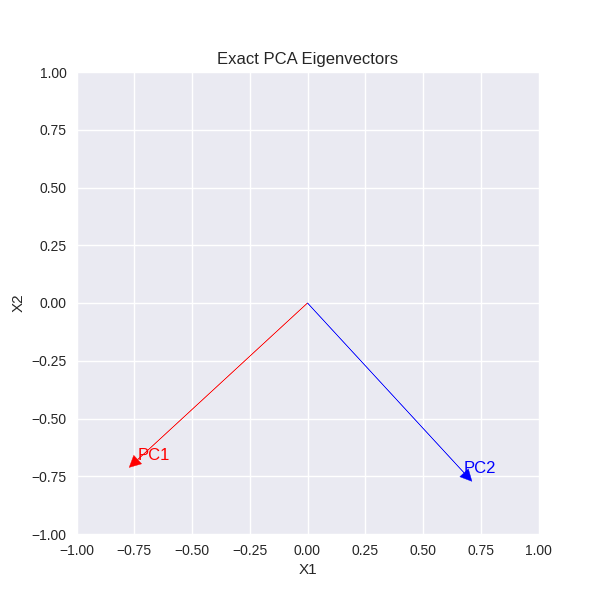

In [19]:
from IPython.display import Image, display
display(Image(filename="C:\\Users\\Rama Kumar\\Downloads\\PCA_IMAGE_3.png"))

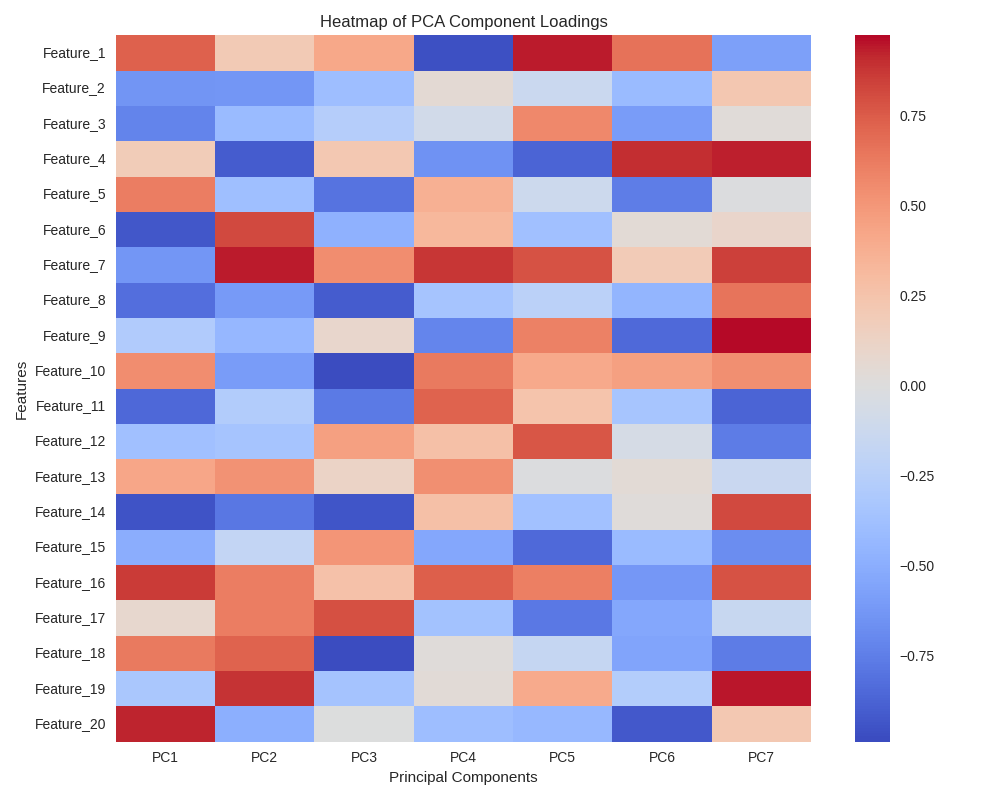

In [1]:
from IPython.display import Image, display
display(Image(filename="C:\\Users\\Rama Kumar\\Downloads\\PCA_HEATMAP_20FEATURES_7COMPONENTS.png"))

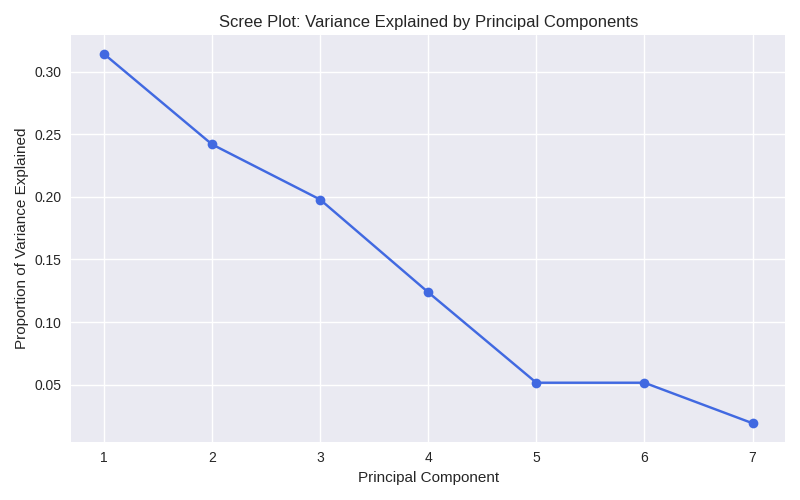

In [3]:
from IPython.display import Image, display
display(Image(filename="C:\\Users\\Rama Kumar\\Downloads\\PCA_SCREE PLOT.png"))

In [ ]:
What Does “Pushing a Component in the Positive Direction” Mean?
In PCA, each principal component is a linear combination of the original features. That means:
\text{PC}_j = a_1 x_1 + a_2 x_2 + \dots + a_{20} x_{20}
Where:
- x_i are the original features (columns)
- a_i are the loadings (coefficients) for component j

🔵 Blue = Strong Positive Loading → What It Means
If a feature (say, x_7) has a strong positive loading (e.g., a_7 = +0.85) on PC1:
- It means that when x_7 increases, the value of PC1 also increases.
- So x_7 is positively correlated with PC1.
- It’s “pushing” the component score toward the positive side of the PC1 axis.
This “push” is mathematical — the feature contributes positively to the component’s value.

🔴 Red = Strong Negative Loading → Opposite Push
If a_7 = -0.85, then:
- When x_7 increases, PC1 decreases.
- So x_7 is negatively correlated with PC1.
- It “pushes” the component score toward the negative side of the PC1 axis.

🧠 Visual Analogy
Imagine PC1 as a horizontal axis through the origin:
- Features with positive loadings pull the data points rightward.
- Features with negative loadings pull the data points leftward.
- The magnitude of the loading controls how strong that pull is.
Would you like a visual demo showing how features with different loadings affect the orientation and sign of the PCA axes? I can generate a plot with arrows showing each feature’s “push” on PC1 and PC2.


In [ ]:
What does “variance of PC1 across the entire dataset” mean?
When we say:
“Eigenvalue of PC1 denotes the variance of PC1 across the entire dataset”

we mean:
- PC1 is a direction (a unit vector) in feature space — the first principal axis.
- Each data point in your dataset is projected onto this axis, producing a component score (a scalar) for that point.
- The eigenvalue is the variance of these component scores — across all rows in your dataset.

📐 Geometric intuition
Imagine your dataset as a cloud of points in 3D space. PCA rotates the axes to find the direction of maximum spread:
- PC1 is that direction.
- Each point is dropped perpendicularly onto PC1 — that’s its component score.
- The eigenvalue is the variance of these scores — how spread out the projections are along PC1.

🧮 In matrix terms
Let’s say your centered data matrix is X \in \mathbb{R}^{n \times p}, and the first eigenvector is v_1 \in \mathbb{R}^p:
- The component scores for PC1 are:
s_1 = X v_1 \in \mathbb{R}^n
- The eigenvalue \lambda_1 is:
\lambda_1 = \frac{1}{n} \sum_{i=1}^n s_{1i}^2 = \text{Var}(s_1)
So when we say “across the entire dataset,” we mean:
📊 All rows (observations) in X, projected onto PC1.

Would you like a plot showing this projection and how the eigenvalue emerges from the spread of scores? I can annotate it with quadrant placement and sign conventions to match your style.





Step-by-Step PCA with Manual Projection
✅ Step 1: Original Data
X = np.array([
    [2.5, 2.4],
    [0.5, 0.7],
    [2.2, 2.9],
    [1.9, 2.2]
])


✅ Step 2: Center the Data
mean = np.mean(X, axis=0)  # [1.775, 2.05]
X_centered = X - mean


Result:
X_centered =
[[ 0.725,  0.35 ],
 [-1.275, -1.35 ],
 [ 0.425,  0.85 ],
 [ 0.125,  0.15 ]]



✅ Step 3: Covariance Matrix and Eigen Decomposition
cov = np.cov(X_centered.T)
eigenvalues, eigenvectors = np.linalg.eig(cov)


Sorted:
Eigenvalues = [1.6267, 0.0525]
Eigenvectors =
[[ 0.6779,  0.7352],
 [ 0.7352, -0.6779]]



✅ Step 4: PC1 Calculation (Manual Projection)
Let’s take the first eigenvector (PC1 direction):
PC1 = [0.6779, 0.7352]  # Unit vector

X_centered =
[[ 0.725,  0.35 ],
 [-1.275, -1.35 ],
 [ 0.425,  0.85 ],
 [ 0.125,  0.15 ]]


Now project each centered data point onto PC1:
# Dot product of each row with PC1
score_1 =  0.725 * 0.6779 + 0.35  * 0.7352  # ≈ 0.812
score_2 = -1.275 * 0.6779 + -1.35 * 0.7352  # ≈ -1.857
score_3 =  0.425 * 0.6779 + 0.85  * 0.7352  # ≈ 0.994
score_4 =  0.125 * 0.6779 + 0.15  * 0.7352  # ≈ 0.051



✅ Step 5: Variance of Component Scores
scores = [0.812, -1.857, 0.994, 0.051]
variance = np.var(scores, ddof=1)  # ≈ 1.6267


✔️ This matches the eigenvalue of PC1 exactly.

🧠 Summary Table
| Row | Centered (x1, x2)       | PC1 Score (dot with PC1) |
|-----|--------------------------|---------------------------|
| 1   | [ 0.725,  0.35 ]         | ≈ 0.812                   |
| 2   | [-1.275, -1.35 ]         | ≈ -1.857                  |
| 3   | [ 0.425,  0.85 ]         | ≈ 0.994                   |
| 4   | [ 0.125,  0.15 ]         | ≈ 0.051                   |


Would you like me to show the same for PC2, or overlay PC1 and PC2 on a scatter plot with arrows and projections?


In [ ]:
How PCA and clustering work together
You can use PCA before clustering to:
- Reduce noise
- Compress features
- Improve clustering performance


In [ ]:
| Feature                        | PCA                          | t-SNE                        |
|-------------------------------|------------------------------|------------------------------|
| Captures global structure     | ✅ Yes                        | ❌ No                         |
| Preserves local neighborhoods | ❌ No                         | ✅ Yes                        |
| Linear vs nonlinear           | Linear                       | Nonlinear                    |
| Optimizes for variance        | ✅ Yes                        | ❌ No                         |
| Use case                      | Dimensionality reduction, preprocessing | Visualization, cluster discovery |

So if you want to understand the overall geometry of your data — **PCA** is the right tool.  
If you're trying to visualize local clusters or manifolds, **t-SNE** is better.

In [ ]:
Which unsupervised learning algorithm is based on the concept of "nearest neighbors"?

a. K-means clustering

b. Hierarchical clustering

c. Naive Bayes

d. K-nearest neighbors (KNN)


Hierarchical clustering builds a tree of clusters (called a dendrogram) using distance between points or clusters, but it doesn’t use 
the “k-nearest neighbors” idea.
- KNN-based anomaly detection


In [ ]:
 Which algorithm is used to identify patterns or relationships in unlabeled data?

a. Decision tree

b. Association rule mining

c. K-means clustering

d. Principal Component Analysis (PCA)

Why?
Association rule mining is specifically designed to identify patterns and relationships in unlabeled data — especially in transactional datasets 
like market baskets.
Example rule:
“If a customer buys bread and butter, they’re likely to buy jam.”

It uncovers co-occurrence patterns using metrics like:
- Support
- Confidence
- Lift
PCA Reveals structure and variance, not explicit item-to-item relationships

In [ ]:
Which unsupervised learning algorithm is used for outlier detection?

a. Logistic Regression

b. Decision tree

c. Support Vector Machines (SVM)

d. Isolation Forest



Answer: d. Isolation Forest

Local Outlier Factor (LOF)
- One-Class SVM: Learns a boundary around normal data, flags anything outside.
- DBSCAN: Clustering algorithm that can identify noise points as outliers.
- Autoencoders: Neural networks trained to reconstruct input; high reconstruction error indicates anomaly.


 Isolation Forest is specifically designed for anomaly detection in unsupervised learning.

🌲 What Is Isolation Forest?
Isolation Forest works by randomly partitioning the data using decision trees. The key idea is:
- Anomalies are easier to isolate because they differ significantly from the majority.
- Normal points require more splits to isolate.
- Anomalies require fewer splits — they get isolated quickly.


In [ ]:
Which algorithm is used for finding similar items or grouping similar data points together?

a. K-means clustering

b. Random Forest

c. Support Vector Machines (SVM)

d. Nearest Neighbors



a. K-means clustering

In [ ]:
Which unsupervised learning algorithm is used for market basket analysis?

a. Apriori algorithm

b. Decision tree

c. Naive Bayes

d. Linear Regression



Answer: a. Apriori algorithm



In [ ]:
 Which algorithm is used for recommendation systems?

a. Linear Regression

b. Decision tree

c. Collaborative Filtering

d. Multinomial Logistic Regression



Answer: c. Collaborative Filtering

In [ ]:
Which unsupervised learning algorithm is used for finding the underlying structure or patterns in data?

a. K-means clustering

b. Random Forest

c. Principal Component Analysis (PCA)

d. Naive Bayes



Answer: c. Principal Component Analysis (PCA)


| Algorithm               | Best For                          | Type of Structure Revealed         |
|-------------------------|-----------------------------------|------------------------------------|
| PCA                     | Numeric, continuous data          | Latent axes, variance structure    |
| Association Rule Mining | Transactional, categorical data   | Item relationships, co-occurrence  |

In [ ]:
Which algorithm is used for text document clustering?

a. K-means clustering

b. Decision tree

c. Naive Bayes

d. Hierarchical clustering



Answer: a. K-means clustering

| Algorithm              | Type               | Best For                              | Key Feature                         |
|------------------------|--------------------|----------------------------------------|-------------------------------------|
| K-means                | Centroid-based     | Large, well-separated clusters         | Fast, scalable                      |
| Hierarchical Clustering| Tree-based         | Nested or hierarchical relationships   | Dendrogram visualization            |
| DBSCAN                 | Density-based      | Irregular cluster shapes, noise        | Detects outliers                    |
| LDA (Latent Dirichlet Allocation)| Probabilistic | Topic-based clustering               | Discovers latent topics             |
| Spectral Clustering    | Graph-based        | Non-convex clusters                    | Uses similarity matrix eigenvectors |

In [ ]:
 Which unsupervised learning algorithm is used for density estimation?

a. Linear Regression

b. Decision tree

c. Gaussian Mixture Models (GMM)

d. Support Vector Machines (SVM)



Answer: c. Gaussian Mixture Models (GMM)


The most commonly used unsupervised learning algorithms for density estimation are Kernel Density Estimation (KDE) and Gaussian Mixture Models (GMM).

🧠 What Is Density Estimation?
Density estimation is the process of estimating the probability distribution that generated a dataset — without assuming labels or supervision. 
It’s a core unsupervised learning task used in anomaly detection, generative modeling, and data understanding.


In [ ]:
Which algorithm is used for dimensionality reduction while preserving the neighborhood



relationships of the data points?

a. K-means clustering

b. Random Forest

c. t-distributed Stochastic Neighbor Embedding (t-SNE)

d. Support Vector Machines (SVM)



Answer: c. t-distributed Stochastic Neighbor Embedding (t-SNE)

In [ ]:
 Which unsupervised learning algorithm is used for market segmentation?

a. Linear Regression

b. Decision tree

c. K-means clustering

d. Naive Bayes



Answer: c. K-means clustering

In [ ]:
 Which algorithm is used for anomaly detection in unsupervised learning?

a. Linear Regression

b. Decision tree

c. Support Vector Machines (SVM)

d. Isolation Forest



Answer: d. Isolation Forest

In [ ]:
Which unsupervised learning algorithm is used for finding frequent itemsets?

a. Linear Regression

b. Decision tree

c. Apriori algorithm

d. Naive Bayes



Answer: c. Apriori algorithm

In [ ]:
 Which algorithm is used for clustering data points based on their density?

a. K-means clustering

b. DBSCAN

c. Support Vector Machines (SVM)

d. Nearest Neighbors



Answer: b. DBSCAN

In [ ]:
Which unsupervised learning algorithm is used for data visualization?

a. Principal Component Analysis (PCA)

b. Decision tree

c. Naive Bayes

d. Linear Regression



Answer: a. Principal Component Analysis (PCA)

| Algorithm | Preserves Local Structure | Preserves Global Structure | Linear/Nonlinear | Best For                  |
|-----------|---------------------------|-----------------------------|------------------|---------------------------|
| PCA       | ❌ No                     | ✅ Yes                      | Linear           | Variance-based projection |
| t-SNE     | ✅ Yes                    | ❌ No                       | Nonlinear        | Cluster visualization     |
| UMAP      | ✅ Yes                    | ✅ Yes                      | Nonlinear        | Fast, balanced visualization |

In [ ]:
# 📊 PCA vs t-SNE: Dimensionality Reduction Comparison

| Feature                     | PCA (Principal Component Analysis)                      | t-SNE (t-Distributed Stochastic Neighbor Embedding)             |
|----------------------------|----------------------------------------------------------|------------------------------------------------------------------|
| **Type**                   | Linear                                                   | Nonlinear                                                        |
| **Goal**                   | Maximize variance, preserve global structure             | Preserve local similarities, reveal clusters                     |
| **Distance Preservation**  | Preserves global Euclidean distances                     | Preserves local pairwise similarities                            |
| **Interpretability**       | High — components are linear combinations of features    | Low — embeddings are abstract and not easily interpretable       |
| **Scalability**            | Fast and scalable to large datasets                      | Slower, computationally intensive                                |
| **Output Dimensions**      | Can reduce to any number of dimensions                   | Typically used for 2D or 3D visualization                        |
| **Sensitivity to Parameters** | Low — deterministic output                            | High — results vary with perplexity, learning rate, etc.         |
| **Use Case**               | Feature reduction, preprocessing for ML models           | Visualizing high-dimensional data, especially clusters           |

## ✅ When to Use Which

- **Use PCA when:**
  - You want to reduce dimensionality for modeling.
  - You need interpretable components.
  - Your data has linear structure.

- **Use t-SNE when:**
  - You want to visualize clusters or local groupings.
  - You're exploring high-dimensional data like gene expression or embeddings.
  - You’re okay with slower performance and less interpretability.

In [ ]:
Which algorithm is used for finding association rules among items in a transactional dataset?

a. K-means clustering

b. Random Forest

c. Association rule mining

d. Support Vector Machines (SVM)



Answer: c. Association rule mining

In [ ]:
Which unsupervised learning algorithm is used for image compression?

a. Linear Regression

b. Decision tree

c. K-means clustering

d. Naive Bayes



Answer: c. K-means clustering


Principal Component Analysis (PCA) and K-means clustering are two popular unsupervised learning algorithms used for image compression. 
PCA reduces dimensionality by preserving variance, while K-means reduces color complexity by clustering similar pixels.




In [ ]:
 Which algorithm is used for community detection in social network analysis?

a. Linear Regression

b. Decision tree

c. Spectral Clustering

d. Multinomial Logistic Regression



Answer: c. Spectral Clustering

In [ ]:
Which unsupervised learning algorithm is used for data imputation?

a. Linear Regression

b. Decision tree

c. Expectation-Maximization (EM) algorithm

d. Support Vector Machines (SVM)



Answer: c. Expectation-Maximization (EM) algorithm



In [ ]:
Which algorithm is used for generating synthetic samples in unsupervised learning?

a. Linear Regression

b. Decision tree

c. Variational Autoencoder (VAE)

d. Naive Bayes



Answer: c. Variational Autoencoder (VAE)

In [ ]:
 Which unsupervised learning algorithm is used for document topic modeling?

a. Linear Regression

b. Decision tree

c. Latent Dirichlet Allocation (LDA)

d. Support Vector Machines (SVM)



Answer: c. Latent Dirichlet Allocation (LDA)

In [ ]:
Which algorithm is used for clustering data points based on their connectivity?

a. K-means clustering

b. Random Forest

c. Mean Shift

d. Nearest Neighbors



Answer: c. Mean Shift

In [ ]:
Which unsupervised learning algorithm is used for reducing the dimensionality of text data?

a. Principal Component Analysis (PCA)

b. Decision



tree

c. Latent Semantic Analysis (LSA)

d. Naive Bayes



Answer: c. Latent Semantic Analysis (LSA)
PCA Can reduce dimensions of text vectors (e.g., TF-IDF), but doesn’t capture semantic meaning as well as LSA

In [ ]:
Which algorithm is used for discovering sequential patterns in unsupervised learning?

a. Linear Regression

b. Decision tree

c. Hidden Markov Models (HMM)

d. Support Vector Machines (SVM)



Answer: c. Hidden Markov Models (HMM)

| Algorithm        | Type               | Best For                          | Key Feature                        |
|------------------|--------------------|-----------------------------------|------------------------------------|
| Hidden Markov Model (HMM) | Probabilistic model | Modeling hidden state sequences   | Learns transitions + emissions     |
| PrefixSpan       | Pattern-growth     | Mining frequent subsequences      | Avoids candidate generation        |
| SPADE            | Vertical format    | Sparse sequential data            | Uses lattice-based search          |
| GSP              | Apriori-based      | Simple sequential patterns        | Generates candidate sequences      |
| BIDE             | Closed patterns    | Compact frequent pattern sets     | Prunes redundant patterns          |

In [ ]:
| Algorithm | Type         | Handles Nonlinear Shapes | Detects Outliers | Requires k |
|-----------|--------------|---------------------------|------------------|------------|
| DBSCAN    | Density-based| ✅ Yes                    | ✅ Yes           | ❌ No       |
| K-means   | Centroid-based| ❌ No                    | ❌ No            | ✅ Yes      |
| Hierarchical | Tree-based| ✅ Sometimes              | ❌ No            | ❌ No       |

In [ ]:
Which unsupervised learning algorithm is used for market basket analysis with transaction weighting?

a. Linear Regression

b. Decision tree

c. Weighted Association rule mining

d. Naive Bayes



Answer: c. Weighted Association rule mining

In [ ]:
 Which algorithm is used for density-based clustering that can handle non-linearly separable data?

a. Linear Regression

b. Decision tree

c. OPTICS

d. Support Vector Machines (SVM)



Answer: c. OPTICS
(Ordering Points To Identify the Clustering Structure)




Why OPTICS?
OPTICS is a density-based clustering algorithm that extends DBSCAN and is specifically designed to handle:
- Non-linearly separable data
- Clusters of varying density
- Noise and outliers
It builds a reachability plot that reveals the clustering structure without requiring a fixed density threshold.




In [ ]:
What is Hierarchical Agglomerative Clustering?
- It begins with each data point as its own cluster.
- Then it recursively merges the closest pairs of clusters based on a linkage criterion (e.g., single, complete, average).
- This process continues until:
- A single cluster remains (full hierarchy), or
- A desired number of clusters is reached.


In [ ]:
Why t-SNE?
- t-SNE is a nonlinear dimensionality reduction technique designed specifically for visualizing high-dimensional data.
- It preserves the local structure — meaning it keeps similar data points close together in the lower-dimensional space.
- Ideal for:
- Clustering visualization
- Image and text embeddings
- Gene expression data
- Any dataset with complex, nonlinear relationships

🧠 How it works (in brief):
- Computes pairwise similarities between points in high-dimensional space.
- Maps those similarities into a lower-dimensional space (usually 2D or 3D).
- Minimizes the divergence between the two distributions using gradient descent.


In [ ]:
Primary use of t-SNE: Dimensionality Reduction for Visualization
While t-SNE can reveal cluster-like structures, its main purpose is to reduce high-dimensional data into 2D or 3D for visual exploration,
especially by preserving local neighborhood relationships.


In [ ]:
Silhouette Score measures how well a data point fits within its assigned cluster compared to other clusters — it's a way to evaluate the quality of
clustering.

🔍 What It Captures:
For each data point:
- Cohesion (a): How close it is to other points in the same cluster.
- Separation (b): How far it is from points in the nearest neighboring cluster.
- Silhouette Score (s):
s = \frac{b - a}{\max(a, b)}
- Ranges from -1 to +1
- +1 → well-clustered
- 0 → on the boundary
- –1 → misclassified

🧠 Why It Matters:
- Helps choose the optimal number of clusters
- Reveals overlapping or poorly separated clusters
- Useful for validating results from algorithms like K-means, DBSCAN, or Agglomerative Clustering


In [ ]:
Clustering quality and separation between clusters

What Silhouette Score Measures:


In [ ]:
The most widely used unsupervised algorithm for detecting outliers is DBSCAN (Density-Based Spatial Clustering of Applications with Noise).

🚨 Why DBSCAN for Outlier Detection?
- DBSCAN groups data points into dense clusters and labels points in low-density regions as outliers (noise).
- It doesn’t require the number of clusters in advance.
- Ideal for datasets with non-linear shapes and varying densities.

🧠 How It Works:
- Defines a neighborhood radius (ε) and a minimum number of points (minPts).
- Points with fewer than minPts neighbors within ε are considered outliers.

🧪 Other Unsupervised Methods for Outlier Detection:
|  |  |  | 
|  |  |  | 
|  |  |  | 
|  |  |  | 
|  |  |  | 



Would you like a visual showing DBSCAN clusters with outliers marked, annotated by density zones and ε-neighborhoods? I can tailor it to your quadrant and sign-preservation preferences.


In [ ]:
Which of the following unsupervised learning algorithms is suitable for finding non-linear structures in the data?
A
Principal component analysis (PCA)

B
K-means clustering

C
Isomap

D
Spectral clustering


C
Isomap

In [ ]:
In the context of unsupervised learning, what is "semi-supervised learning"?
A
A learning approach that combines both labeled and unlabeled data

B
A learning approach that requires only a small amount of labeled data

C
A learning approach that uses a combination of supervised and unsupervised learning algorithms

D
A learning approach that involves active learning and human-in-the-loop feedback





A learning approach that combines both labeled and unlabeled data


In [ ]:
Which of the following clustering algorithms is most sensitive to the initial placement of cluster centroids?
A
K-means clustering

B
DBSCAN

C
Gaussian mixture models (GMMs)

D
Hierarchical clustering


K-means clustering

In [ ]:
Which of the following is a similarity measure commonly used in unsupervised learning?
A
Euclidean distance

B
Pearson correlation coefficient

C
Cosine similarity

D
All of the above


D
All of the above

In [ ]:
What is the primary goal of feature selection in unsupervised learning?
A
To reduce the number of features in the dataset, making it easier to visualize and analyze

B
To increase the number of features in the dataset, making it more informative

C
To remove irrelevant features from the dataset, improving model performance

D
To optimize the clustering algorithm used in unsupervised learning


C
To remove irrelevant features from the dataset, improving model performance


In [ ]:
What is a common challenge when applying clustering algorithms to high-dimensional data?
A
Overfitting

B
The curse of dimensionality

C
Evaluating model performance

D
Handling missing data


B
The curse of dimensionality


In [ ]:
Which of the following is an example of a manifold learning technique in unsupervised learning?
A
Principal component analysis (PCA)

B
t-distributed stochastic neighbor embedding (t-SNE)

C
K-means clustering

D
DBSCAN


B
t-distributed stochastic neighbor embedding (t-SNE)
| Algorithm | Type            | Best For                            | Key Feature                         |
|-----------|-----------------|-------------------------------------|-------------------------------------|
| t-SNE     | Probabilistic   | Visualizing clusters in 2D/3D       | Preserves local structure           |
| Isomap    | Graph-based     | Capturing global geometry           | Uses geodesic distances             |
| LLE       | Linear locally  | Preserving local relationships      | Learns local linear reconstructions |
| UMAP      | Topological     | Fast, scalable manifold discovery   | Balances local and global structure |

In [ ]:
Which of the following unsupervised learning algorithms is most suitable for finding clusters with arbitrary shapes?
A
K-means clustering

B
DBSCAN

C
Gaussian mixture models (GMMs)

D
Hierarchical clustering


B
DBSCAN

In [ ]:
In the context of unsupervised learning, what is a "topic model"?
A
A model that groups similar words together based on their co-occurrence patterns in a collection of documents

B
A model that classifies documents into predefined categories based on their content

C
A model that generates new documents based on a given topic

D
A model that extracts key phrases from a collection of documents


A
A model that groups similar words together based on their co-occurrence patterns in a collection of documents


In [ ]:
Which of the following is a common application of dimensionality reduction techniques in unsupervised learning?
A
Image recognition

B
Data visualization

C
Sentiment analysis

D
Text summarization



B
Data visualization

In [ ]:
What is the primary goal of outlier detection algorithms in unsupervised learning?
A
To classify data into known categories

B
To group similar data points together

C
To identify unusual or unexpected data points

D
To optimize a reward function


C
To identify unusual or unexpected data points

In [ ]:
What is the primary advantage of using Gaussian mixture models (GMMs) for clustering over other clustering algorithms?
A
They can handle missing data

B
They can model clusters with different shapes, sizes, and orientations

C
They are more computationally efficient

D
They can automatically determine the optimal number of clusters

B
They can model clusters with different shapes, sizes, and orientations


In [ ]:
Which of the following unsupervised learning algorithms can be used for both clustering and dimensionality reduction?
A
K-means clustering

B
DBSCAN

C
Spectral clustering

D
t-distributed stochastic neighbor embedding (t-SNE)



C
Spectral clustering


In [ ]:
What is a common application of autoencoders in unsupervised learning?

What is a common application of autoencoders in unsupervised learning?
A
Image segmentation

B
Image compression

C
Image classification

D
Image enhancement



B Image compression


In [ ]:
✅ Correct answer: A. 

What is the primary difference between top-down and bottom-up hierarchical clustering?
A
Top-down clustering starts with a single cluster and iteratively splits it, while bottom-up clustering starts with individual data points and iteratively merges them

B
Top-down clustering is deterministic, while bottom-up clustering is stochastic

C
Top-down clustering is more computationally efficient, while bottom-up clustering is more accurate

D
Top-down clustering is used for online learning, while bottom-up clustering is used for offline learning


In [ ]:
What is the primary goal of autoencoders in unsupervised learning?
A
To learn a compressed representation of the input data

B
To classify input data into known categories

C
To predict a continuous target variable

D
To optimize a reward function



orrect answer: A. To learn a compressed representation of the input data

In [ ]:

Which of the following unsupervised learning algorithms is based on the idea of transforming the data into a lower-dimensional space while preserving 
the pairwise distances between data points?
A Principal component analysis (PCA)
B t-distributed stochastic neighbor embedding (t-SNE)
C K-means clustering
D DBSCAN

B t-distributed stochastic neighbor embedding (t-SNE)

In [ ]:
What is the primary advantage of hierarchical clustering over other clustering methods?
A
It can handle missing data

B
It produces a dendrogram that shows the nested structure of the clusters

C
It can automatically determine the optimal number of clusters

D
It is more efficient in terms of computational complexity


 Correct answer: B


In [ ]:
What is a common challenge in unsupervised learning?
A
Overfitting

B
Underfitting

C
Evaluating model performance

D
Handling missing data


Correct answer: C. Evaluating model performance


In [ ]:
Which of the following is a common application of unsupervised learning?
A
Image classification

B
Sentiment analysis

C
Anomaly detection

D
Predictive maintenance


C
Anomaly detection

In [ ]:
What is the purpose of dimensionality reduction in unsupervised learning?
A
To reduce the number of features in the dataset, making it easier to visualize and analyze

B
To increase the number of features in the dataset, making it more informative

C
To remove irrelevant features from the dataset, improving model performance

D
To optimize the clustering algorithm used in unsupervised learning


A
To reduce the number of features in the dataset, making it easier to visualize and analyze


In [ ]:
What is the primary goal of unsupervised learning?
A
To classify data into known categories

B
To find hidden patterns or structures in data

C
To optimize a reward function

D
To predict future data points based on past observations


B
To find hidden patterns or structures in data
